# Test images with a chosen noise level: the noise-band tools

This notebook shows how to generate **LOFAR-like images and large maps whose noise lies in a band you choose**,
for example 40–55 µJy/beam, together with the **catalog of every source put into them**. It is meant for testing
source finders: you know exactly what is in the image, and you can test at the noise levels you care about.

It covers:

1. What "noise" means here, and what you get
2. Setup
3. How the noise is controlled, and why the input catalog matters
4. The calibration: from a requested noise to a generated image
5. Generating images in a noise band
6. Testing a source finder against the truth catalog
7. Large maps
8. Limitations, command-line use

Sections 3 and 4 explain the method. Sections 5–7 generate images and need a
GPU and [PyBDSF](https://pybdsf.readthedocs.io). The command-line equivalents are in section 8.

The images are generated by `LDM-Denoiser-WnetCC-rms-v1`, a noise-conditioned version of the latent diffusion model of
Vicánek Martínez & Brüggen (2026), [arXiv:2609.06549](https://arxiv.org/abs/2609.06549). See
`tutorial_getting_started.ipynb` for the model itself and for SWIIT, the sampler used for large maps.

## 1. What "noise" means here, and what you get

Noise is the median of the PyBDSF rms map of an image, run with the LoTSS settings
(`glori.analysis.bdsf_analysis.DEFAULT_KWARGS`; 6" beam, 1.5" pixels, 144 MHz). Every output image has its value written to the FITS header (`NOISE`, in µJy/beam).

You ask for a band, e.g. 40–55 µJy/beam, and a number of images. Each image gets its own noise, drawn log-uniformly within the band. For every image you get:

| Output | Content |
|---|---|
| FITS image | Jy/beam, 512×512 px (single images) or larger (maps) |
| truth catalog | every input source: pixel position, peak and total flux (as in the image and as input), size, real LoTSS-DR3 or synthetic |
| PyBDSF catalog | what PyBDSF finds in the image, as a reference finder |
| rms map | for large maps, where the noise varies across the map |

Requests outside the validated range are refused (section 4 explains where the limits come from).

## 2. Setup

Requirements: the `glori` package (see the repository `README.md`), a working `bdsf` installation for sections 5–7,
a GPU for sections 5–7, and internet access.

On first use, the tools download the necessary models from
[huggingface.co/astrokevin/glori-ldm-swiit](https://huggingface.co/astrokevin/glori-ldm-swiit) and cache them.
Source catalogs are queried from the public [LoTSS-DR3 cone search](https://vo.astron.nl/lotss_dr3/q/src_cone/info).

`glori` keeps its storage under `GLORI_STORAGE_PARENT`. On a new machine, set it before importing `glori` (see the
README); the commented line below does that.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]   # keeps the notebook small

import contextlib
import io
import os
from pathlib import Path

# On a new machine: point glori to a storage directory of your own (see README, "Set the storage directory").
# os.environ["GLORI_STORAGE_PARENT"] = str(Path.home() / "glori_storage")

# PyBDSF runs in single-threaded worker processes; keep numerical libraries single-threaded as well.
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "1")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.spatial import cKDTree

from glori.inference import noise_sampler as ns
from glori.inference.noise_sampler import NoiseBandSampler
from glori.inference.noise_map_sampler import NoiseBandMapSampler

# where the generated images go
OUT = Path(os.environ.get("NOISE_TUTORIAL_OUT", "noise_tutorial_output"))
DEVICE = "cuda:0"

single = NoiseBandSampler(device=DEVICE)       # 512 px images
maps = NoiseBandMapSampler(device=DEVICE)      # large maps (SWIIT)
print("single images: valid noise range %.1f-%.1f uJy/beam" % single.valid_range)
print("large maps:    valid noise range %.1f-%.1f uJy/beam (map median)" % maps.valid_range)

single images: valid noise range 38.9-222.1 uJy/beam
large maps:    valid noise range 50.0-224.0 uJy/beam (map median)


## 3. How the noise is controlled, and why the input catalog matters

You might expect that changing the noise channel would change the noise in the image. On its own, it doesn’t. A real LoTSS catalog is complete down to roughly five times the local noise, so the faintest catalogued sources and the source count already tell the model how deep the image is. If you pair a real catalog from a 60 µJy/beam field with a noise channel of 150 µJy/beam, the model receives contradictory information. It reconciles the two by scaling sources and noise together. The output therefore keeps roughly the depth implied by the catalog, and the source fluxes are scaled up along with the noise.

For this reason, the tools always use a catalog that is consistent with the requested noise. There are two ways to obtain one.

Real depth (below 65 µJy/beam). The simplest consistent catalog is a real one. Pick a patch of the real sky that already has the requested noise level and use its catalog unchanged. The tools keep a list of 54 238 DR3 tiles that match the image size (12.8′). Each tile has its own depth, defined as the median Isl_rms of its sources. In this mode:

there are no synthetic sources,
bright sources appear about as often as they do in the real sky, and
the noise channel contains the real Isl_rms.

The cell below selects tiles for four noise levels.

In [2]:
single._load_base()                                 # downloads the lists of tiles and fields on first use
rng = np.random.default_rng(0)
print(f"{len(single._tiles)} tiles, depth {single._tiles.isl_uJy.min():.0f}-{single._tiles.isl_uJy.max():.0f} uJy/beam")
for s in [40, 47, 55, 64]:
    ra, dec, mode, depth = single._pick_field(s, rng)
    c = ns.fetch_field_context(ra, dec, ns.CTX_SIZE)  # 256 x 256 cells of 6" (25.6'), from the public cone search
    img_area = c[:, 64:192, 64:192]                   # the 512 px image is the central 128 x 128 cells
    print(f"noise {s}: {mode}, tile RA={ra:.2f} Dec={dec:.2f}, catalog noise {depth:.0f}, "
          f"{(img_area[0] > 0).sum()} sources in the image, brightest {img_area[2].max():.1f} mJy")

54238 tiles, depth 30-95 uJy/beam


noise 40: real_depth, tile RA=159.51 Dec=57.07, catalog noise 40, 64 sources in the image, brightest 6.0 mJy


noise 47: real_depth, tile RA=177.88 Dec=52.16, catalog noise 48, 58 sources in the image, brightest 8.5 mJy


noise 55: real_depth, tile RA=200.61 Dec=59.20, catalog noise 55, 91 sources in the image, brightest 4.3 mJy


noise 64: real_depth, tile RA=178.25 Dec=58.99, catalog noise 62, 68 sources in the image, brightest 21.5 mJy


Matched depth (from 65 µJy/beam). At these noise levels, the real-tile approach loses too much flux (see section 4), and shallow fields also become scarce. Instead, the tools build a catalog for a target depth T (in µJy/beam), starting from a random DR3 field whose native noise is at most 90 µJy/beam. The catalog has three parts:

* Real sources: All LoTSS-DR3 sources in the field whose peak flux is at least 8 times the field’s own noise (the level where LoTSS is complete) and at least 3 T.
* Synthetic sources: These fill in below that threshold. Their signal-to-noise ratios, total-to-peak ratios and sizes are drawn from real DR3 sources, and their peak flux is set to SNR × T. They are placed at random positions. Their number matches what a DR3 field of depth T would contain, using a source density that scales as T^−1.26.
* Noise channel: At every source, the noise channel is set to T / 1.07, because the image noise is about 7 % higher than the catalog’s island rms. On top of this, added in quadrature, comes the real noise excess around bright sources, which is how far a real source’s Isl_rms lies above its field’s own noise. Synthetic sources within 2′ of a real source inherit that source’s excess.

The excess is what produces the artefacts. In LoTSS, the spokes and noise peaks around a bright source scale with the source’s brightness, not with the depth of the field; the excess amounts to about 0.1–0.3 % of the source’s peak flux. The model reads these patterns from the noise channel. If the channel is constant, the sources are still generated, but the patterns around them disappear.

The cell below builds these catalogs for one real field at three depths. Like the previous cell, it needs no GPU.

field RA=180.0, Dec=45.0: 184 DR3 sources, native noise 76 uJy/beam


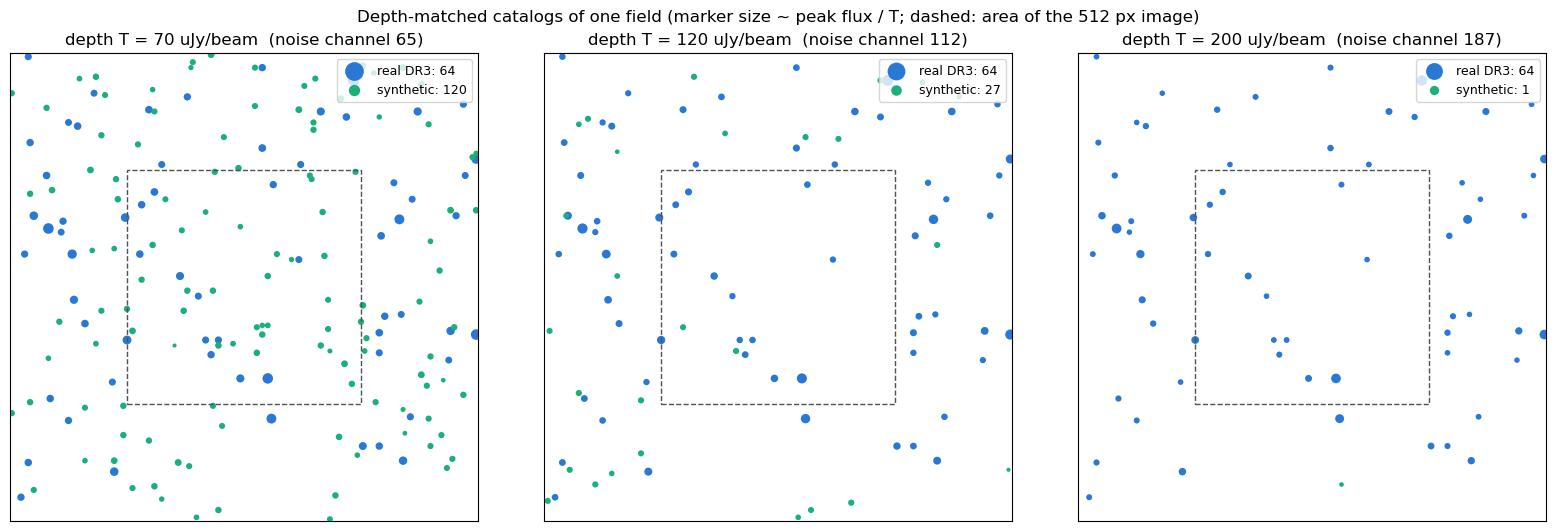

In [3]:
ra, dec = 180.0, 45.0                              # any position covered by LoTSS-DR3
raw = ns.fetch_field_context(ra, dec, ns.CTX_SIZE)
pool = ns.snr_pool()                               # source properties of real DR3 sources
method = single.calib["method"]

src = raw[0] > 0
native = float(np.median(raw[4][src]))             # the field's own noise: median Isl_rms of its sources
print(f"field RA={ra}, Dec={dec}: {src.sum()} DR3 sources, native noise {native:.0f} uJy/beam")

fig, ax = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)
for a, T in zip(ax, [70, 120, 200]):
    c, synthetic = ns.depth_matched_context(raw, float(T), pool, np.random.default_rng(0), method)
    s = c[0] > 0
    real = s & ~synthetic
    for mask, col, lab in [(real, "#2a78d6", "real DR3"), (synthetic, "#1baf7a", "synthetic")]:
        y, x = np.nonzero(mask)
        a.scatter(x, y, s=6 + 20 * np.clip(np.log10(c[2][mask] * 1e3 / T), 0, 3), c=col, lw=0,
                  label=f"{lab}: {mask.sum()}")
    lo, hi = 64, 192                                # the 512 px image is the central 128 x 128 cells
    a.add_patch(plt.Rectangle((lo, lo), hi - lo, hi - lo, fill=False, ec="#52514e", ls="--", lw=1))
    a.set(xlim=(0, 256), ylim=(0, 256), aspect="equal", xticks=[], yticks=[],
          title=f"depth T = {T} uJy/beam  (noise channel {T / method['img_to_isl']:.0f})")
    a.legend(loc="upper right", fontsize=9, markerscale=2)
fig.suptitle("Depth-matched catalogs of one field (marker size ~ peak flux / T; dashed: area of the 512 px image)")
plt.show()

The *same* field gives very different catalogs. Here all real sources kept are above 8 times the field's own
noise at every depth, so they stay the same; what changes is the faint end: at T = 70 many sources in the image are
synthetic, at T = 200 almost none are needed. (In a deeper field, or at T above ~2.7 times the field's noise, the
3 T limit also removes real sources.) The real sources keep their true positions and fluxes, which preserves the
clustering and the bright end of the real sky.

The noise channel of the five brightest sources shows the excess: it stays at T / 1.07 for faint sources and rises
well above it for bright ones, at every depth.

In [4]:
rows = []
for T in [70, 120, 200]:
    c, synthetic = ns.depth_matched_context(raw, float(T), pool, np.random.default_rng(0), method)
    real = (c[0] > 0) & ~synthetic
    count = (c[0][real] + 1) / 2                     # sources per cell: channels are summed per cell
    order = np.argsort(c[2][real])[::-1]
    base = T / method["img_to_isl"]
    rows.append(pd.DataFrame({"T": T, "peak_mJy": c[2][real][order[:5]], "noise_channel_uJy": (c[4][real] / count)[order[:5]],
                              "T / 1.07": base}))
pd.concat(rows, ignore_index=True).round(1)

,T,peak_mJy,noise_channel_uJy,T / 1.07
0,70,79.900002,305.500000,65.4
1,70,30.500000,143.399994,65.4
2,70,27.600000,106.800003,65.4
3,70,26.299999,132.699997,65.4
4,70,12.500000,67.599998,65.4
5,120,79.900002,318.799988,112.1
6,120,30.500000,169.899994,112.1
7,120,27.600000,140.399994,112.1
8,120,26.299999,160.899994,112.1
9,120,12.500000,113.400002,112.1


## 4. The calibration: from a requested noise to a generated image

The generated noise is close to, but not exactly, what the catalog says, so the relation was calibrated. The calibration
files are part of the package (`configs/noise_calibration/`):

- **real depth**: 48 tiles at each of 10 noise levels, each with the real DR3 cutout of the same tile;
- **depth matched, single images**: 69 DR3 fields at 19 depths;
- **depth matched, large maps**: 8 fields at 7 depths (2048 px maps).

The left plot shows the median generated noise and its spread, and the validated range of each tool. The right plot
shows why the modes switch at 65 µJy/beam: above it, the flux of the real-depth images falls below the 10 % limit.

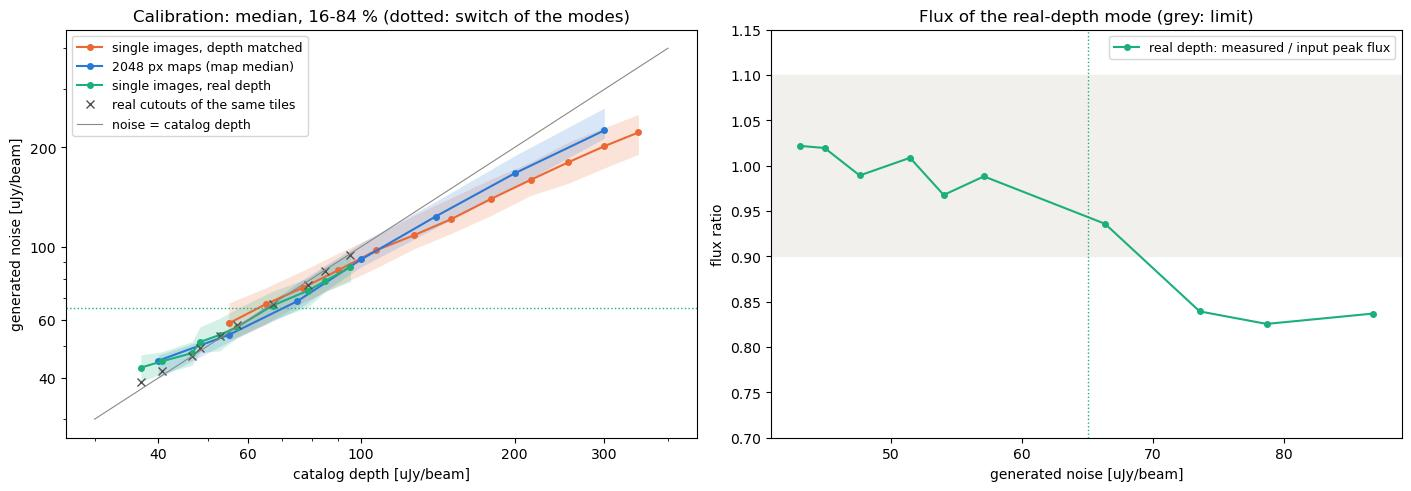

single images: valid 38.9-222.1 uJy/beam | large maps: valid 50.0-224.0 uJy/beam
criteria, single images: {'monotone': 0.95, 'realism': 0.9, 'recovery': 0.95, 'flux_tol': 0.1, 'min_bright_recovery': 0.8, 'max_rescale': 1.3, 'real_texture_pass': 0.9417}
criteria, large maps:    {'max_rescale': 1.3, 'min_texture_frac': 0.75, 'min_bright_recovery': 0.8, 'min_flux_sources': 10, 'flux_snr': 20.0}


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
for s, name, col in [(single, "single images, depth matched", "#eb6834"), (maps, "2048 px maps (map median)", "#2a78d6")]:
    c = s.calib["calibration"]
    t = np.array(c["target"])
    ax[0].fill_between(t, c["noise_p16"], c["noise_p84"], color=col, alpha=0.18, lw=0)
    ax[0].plot(t, c["noise_p50"], "o-", color=col, ms=4, label=name)
rd = pd.DataFrame(single.calib["real_depth"]["table"])
cat_noise = rd.isl_uJy * single.calib["method"]["img_to_isl"]
ax[0].fill_between(cat_noise, rd.noise_p16, rd.noise_p84, color="#1baf7a", alpha=0.18, lw=0)
ax[0].plot(cat_noise, rd.noise_p50, "o-", color="#1baf7a", ms=4, label="single images, real depth")
ax[0].plot(cat_noise, rd.real_noise_p50, "x", color="#52514e", label="real cutouts of the same tiles")
ax[0].plot([30, 400], [30, 400], color="#8a8984", lw=0.8, label="noise = catalog depth")
ax[0].axhline(single.calib["real_depth"]["max_noise_uJy"], color="#1baf7a", ls=":", lw=1)
ax[0].set(xscale="log", yscale="log", xlabel="catalog depth [uJy/beam]", ylabel="generated noise [uJy/beam]",
          title="Calibration: median, 16-84 % (dotted: switch of the modes)")
ax[0].legend(fontsize=9)
ax[1].axhspan(0.9, 1.1, color="#f1f0ec")
ax[1].plot(rd.noise_p50, rd.flux, "o-", color="#1baf7a", ms=4, label="real depth: measured / input peak flux")
ax[1].axvline(single.calib["real_depth"]["max_noise_uJy"], color="#1baf7a", ls=":", lw=1)
ax[1].set(xlabel="generated noise [uJy/beam]", ylabel="flux ratio", ylim=(0.7, 1.15), title="Flux of the real-depth mode (grey: limit)")
ax[1].legend(fontsize=9)
ax[0].set_xticks([40, 60, 100, 200, 300], labels=["40", "60", "100", "200", "300"])
ax[0].set_yticks([40, 60, 100, 200], labels=["40", "60", "100", "200"])
plt.show()

print("single images: valid %.1f-%.1f uJy/beam" % single.valid_range, "| large maps: valid %.1f-%.1f uJy/beam" % maps.valid_range)
print("criteria, single images:", single.calib["criteria"])
print("criteria, large maps:   ", maps.calib["criteria"])

How one image is made - for a request of e.g. 40–55 µJy/beam:

1. draw a target noise s log-uniformly in the band, e.g. 47.3 µJy/beam;
2. pick the catalog: below 65 µJy/beam a tile whose depth gives s; from 65 µJy/beam the depth T whose median generated
   noise is s (`single.depth_for_noise(s)`), and the depth-matched catalog of a random DR3 field;
3. generate the image and measure its noise σ with PyBDSF;
4. rescale the image by s / σ, so its noise is exactly s. PyBDSF is linear: a rescaled image has a rescaled rms
   map and catalog, with the same detections. Because the model scales sources and noise together, the rescale keeps
   the image self-consistent, and the truth catalog's fluxes follow it (see below). 90 % of the rescales are within 0.83–1.20;
5. quality checks: an image is dropped and replaced if it needs a rescale above ×1.3, if its noise texture
   (grain size, positive and negative outliers, stripes) lies outside the range of real DR3 cutouts at that noise, or
   if more than 20 % of its bright input sources (≥ 10σ) are missing.

Where the limits come from: The lower limit, 38.9 µJy/beam, is the 16 % noise of the lowest calibrated tile level; only
about 1 % of real DR3 tiles are that deep. Above ~222 µJy/beam the noise still rises, but bright sources are missed more
often than the criteria allow. For large maps the lower limit is 50 µJy/beam, because below it too many 512 px tiles have
striped noise.

In [ ]:
rng = np.random.default_rng(1)
for s in [40, 47.3, 60, 65, 100, 200]:
    _, _, mode, depth = single._pick_field(s, rng)
    print(f"requested noise {s:6.1f} uJy/beam -> {mode:13s} catalog depth {depth:6.1f} uJy/beam")

try:
    single.check_band(30, 50)
except ValueError as e:
    print("\nrefused:", e)

requested noise   40.0 uJy/beam -> real_depth    catalog depth   37.7 uJy/beam
requested noise   47.3 uJy/beam -> real_depth    catalog depth   47.6 uJy/beam
requested noise   60.0 uJy/beam -> real_depth    catalog depth   63.5 uJy/beam
requested noise   65.0 uJy/beam -> depth_matched catalog depth   62.6 uJy/beam
requested noise  100.0 uJy/beam -> depth_matched catalog depth  111.5 uJy/beam
requested noise  200.0 uJy/beam -> depth_matched catalog depth  296.3 uJy/beam

refused: Noise band 30-50 uJy/beam is outside the validated range 38.9-222.1 uJy/beam of rms-v1.json.


What the truth catalog says about flux: The catalog holds the flux in the image, which is not the flux in the sky:

`peak_flux = peak_flux_input × image flux factor × brightness factor`

- The image flux factor comes from the image's own sources when it has at least 5 with an input peak ≥ 20σ, otherwise from
  the calibration (`flux_factor_from` in `summary.csv`, `FLUXFAC` in the header).
- The **brightness factor** exists because the denoiser compresses bright sources. The compression follows the input SNR
  (input peak / noise of the image), so the same source loses more at low noise. It was measured on end-to-end runs of
  the tools, including runs on fields chosen for their bright sources, and maps have their own curve. It is the same for
  real-depth and depth-matched images.

The plot shows both curves. Below SNR 20 they are not measured and return to 1 at SNR 10; above the last point they stay
constant. `total_flux` has its own, flatter curves. The images themselves are not corrected, so a 1 Jy source at 50 µJy/beam
appears at about 0.27 Jy, and the truth catalog says so.

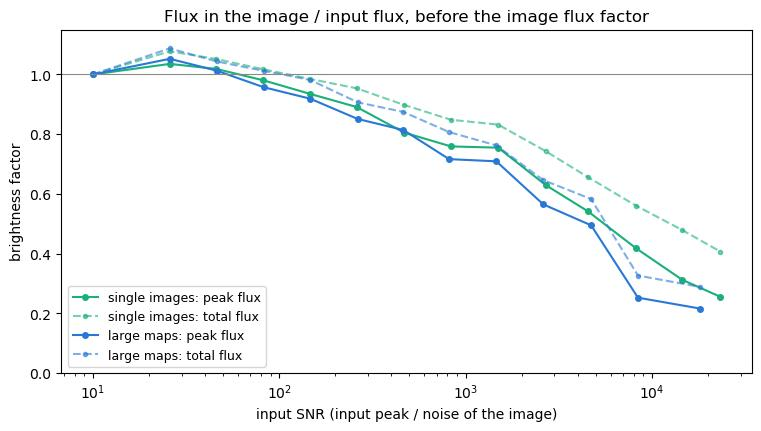

brightness factor (peak) of a source at 50 uJy/beam, single images:
 input_mJy     snr  factor
       1.0    20.0    1.03
      10.0   200.0    0.91
     100.0  2000.0    0.69
    1000.0 20000.0    0.27


In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.2), constrained_layout=True)
for s, name, col in [(single, "single images", "#1baf7a"), (maps, "large maps", "#2a78d6")]:
    b = s.calib["brightness"]
    ax.plot(b["snr"], b["peak"], "o-", color=col, ms=4, label=f"{name}: peak flux")
    ax.plot(b["snr"], b["total"], "o--", color=col, ms=3, alpha=0.6, label=f"{name}: total flux")
ax.axhline(1, color="#8a8984", lw=0.8)
ax.set(xscale="log", xlabel="input SNR (input peak / noise of the image)", ylabel="brightness factor", ylim=(0, 1.15),
       title="Flux in the image / input flux, before the image flux factor")
ax.legend(fontsize=9)
plt.show()

truth_example = pd.DataFrame({"peak_flux_input": [0.001, 0.01, 0.1, 1.0]})
print("brightness factor (peak) of a source at 50 uJy/beam, single images:")
print(pd.DataFrame({"input_mJy": truth_example.peak_flux_input * 1e3,
                    "snr": truth_example.peak_flux_input * 1e6 / 50,
                    "factor": single.brightness_factors(truth_example, 50.0)[0].round(2)}).to_string(index=False))

## 5. Generating images in a noise band

`sample` generates the requested number of images that pass the checks and writes them, with catalogs and a report,
to `out_dir`. PyBDSF runs in parallel single-core processes while the GPU generates the next batch. On an A100, 16 images take about a minute.

In [8]:
run = OUT / "images_40-55"
with contextlib.redirect_stdout(io.StringIO()):   # hides the samplers' configuration printout
    report = single.sample(40, 55, n=8, out_dir=run, seed=0)
print(json.dumps({k: report[k] for k in ["n_kept", "n_generated", "rejected", "noise_kept_uJy", "seconds"]}, indent=1))

summary = pd.read_csv(run / "summary.csv")
truth = pd.read_csv(run / "truth_catalog.csv")
found = pd.read_csv(run / "pybdsf_catalog.csv")
summary[["image_id", "file", "noise_uJy", "rescale", "mode", "depth_uJy", "flux_factor", "flux_factor_from", "field_ra", "field_dec"]].round(3)

{
 "n_kept": 8,
 "n_generated": 8,
 "rejected": {},
 "noise_kept_uJy": {
  "min": 40.21,
  "p50": 48.76,
  "max": 53.49
 },
 "seconds": 58
}


,image_id,file,noise_uJy,rescale,mode,depth_uJy,flux_factor,flux_factor_from,field_ra,field_dec
0,0,images/img_00000.fits,48.995,1.023,real_depth,49.627,0.994,image,221.983,51.307
1,1,images/img_00001.fits,51.825,0.863,real_depth,48.097,0.838,calibration,176.737,51.520
2,2,images/img_00002.fits,53.493,0.869,real_depth,55.362,0.940,image,181.007,49.813
3,3,images/img_00003.fits,48.524,1.103,real_depth,49.691,0.924,image,203.879,48.320
4,4,images/img_00004.fits,50.460,1.064,real_depth,43.570,1.140,image,239.475,50.667
5,5,images/img_00005.fits,40.525,0.964,real_depth,38.231,0.986,image,155.107,55.147
6,6,images/img_00006.fits,40.211,0.897,real_depth,40.371,1.006,image,147.947,51.733
7,7,images/img_00007.fits,43.589,1.010,real_depth,39.205,1.354,image,153.936,56.000


Every image, its truth catalog and the PyBDSF catalog share `image_id`. Positions are in pixels (0-based,
`x_px` = column), fluxes in Jy. Below, three images on a common intensity scale, with the truth catalog.

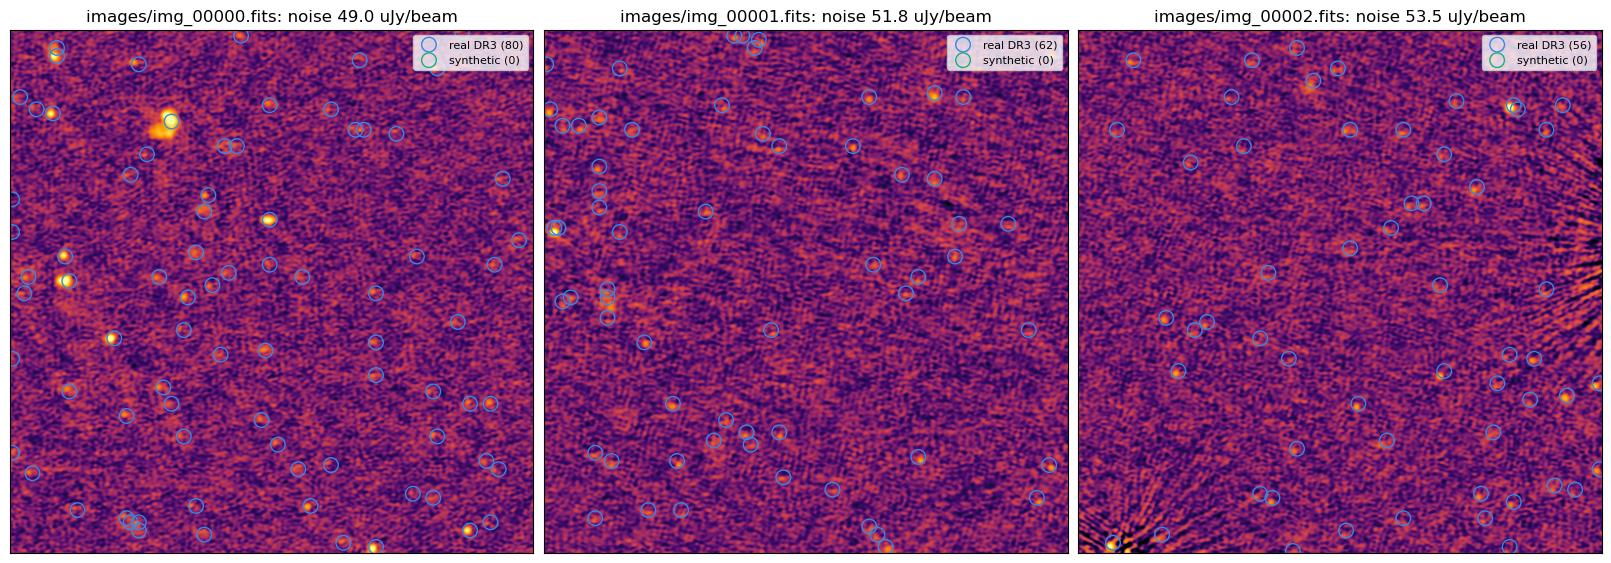

In [9]:
def show(img_uJy, ax, soft=60, vmin=-300, vmax=3000):
    st = lambda a: np.arcsinh(a / soft)   # linear around the noise, logarithmic for bright sources
    return ax.imshow(st(img_uJy), origin="lower", cmap="inferno", vmin=st(vmin), vmax=st(vmax))

fig, ax = plt.subplots(1, 3, figsize=(16, 5.6), constrained_layout=True)
for a, (_, s) in zip(ax, summary.head(3).iterrows()):
    img = fits.getdata(run / s.file) * 1e6
    show(img, a)
    t = truth[truth.image_id == s.image_id]
    for syn, col, lab in [(False, "#3987e5", "real DR3"), (True, "#1baf7a", "synthetic")]:
        q = t[t.synthetic == syn]
        a.scatter(q.x_px, q.y_px, s=110, facecolors="none", edgecolors=col, lw=1, label=f"{lab} ({len(q)})")
    a.set(xticks=[], yticks=[], title=f"{s.file}: noise {s.noise_uJy:.1f} uJy/beam")
    a.legend(loc="upper right", fontsize=8)
plt.show()

Different noise levels: For several noise levels, make one run per band. The cell below requests four bands with
four images each (about 3 minutes) and plots them on the same intensity scale, so the noise can be compared by eye.

- The noise rises from row to row, and every image lies within its band.
- The number of sources falls, because the catalog has to fit the depth of the image (section 3): faint sources a real
  image of this noise would not show are not put in.
- Spokes and noise peaks around bright sources appear at every level, though not around every bright source.
- The upper two rows are real depth, each image from its own real tile. The lower two are depth matched: with the
  same `seed` they start from the same DR3 fields, so a column shows the same bright sources at two noise levels. This is
  not the same sky twice: each image is generated separately, and the fainter sources and the noise differ.

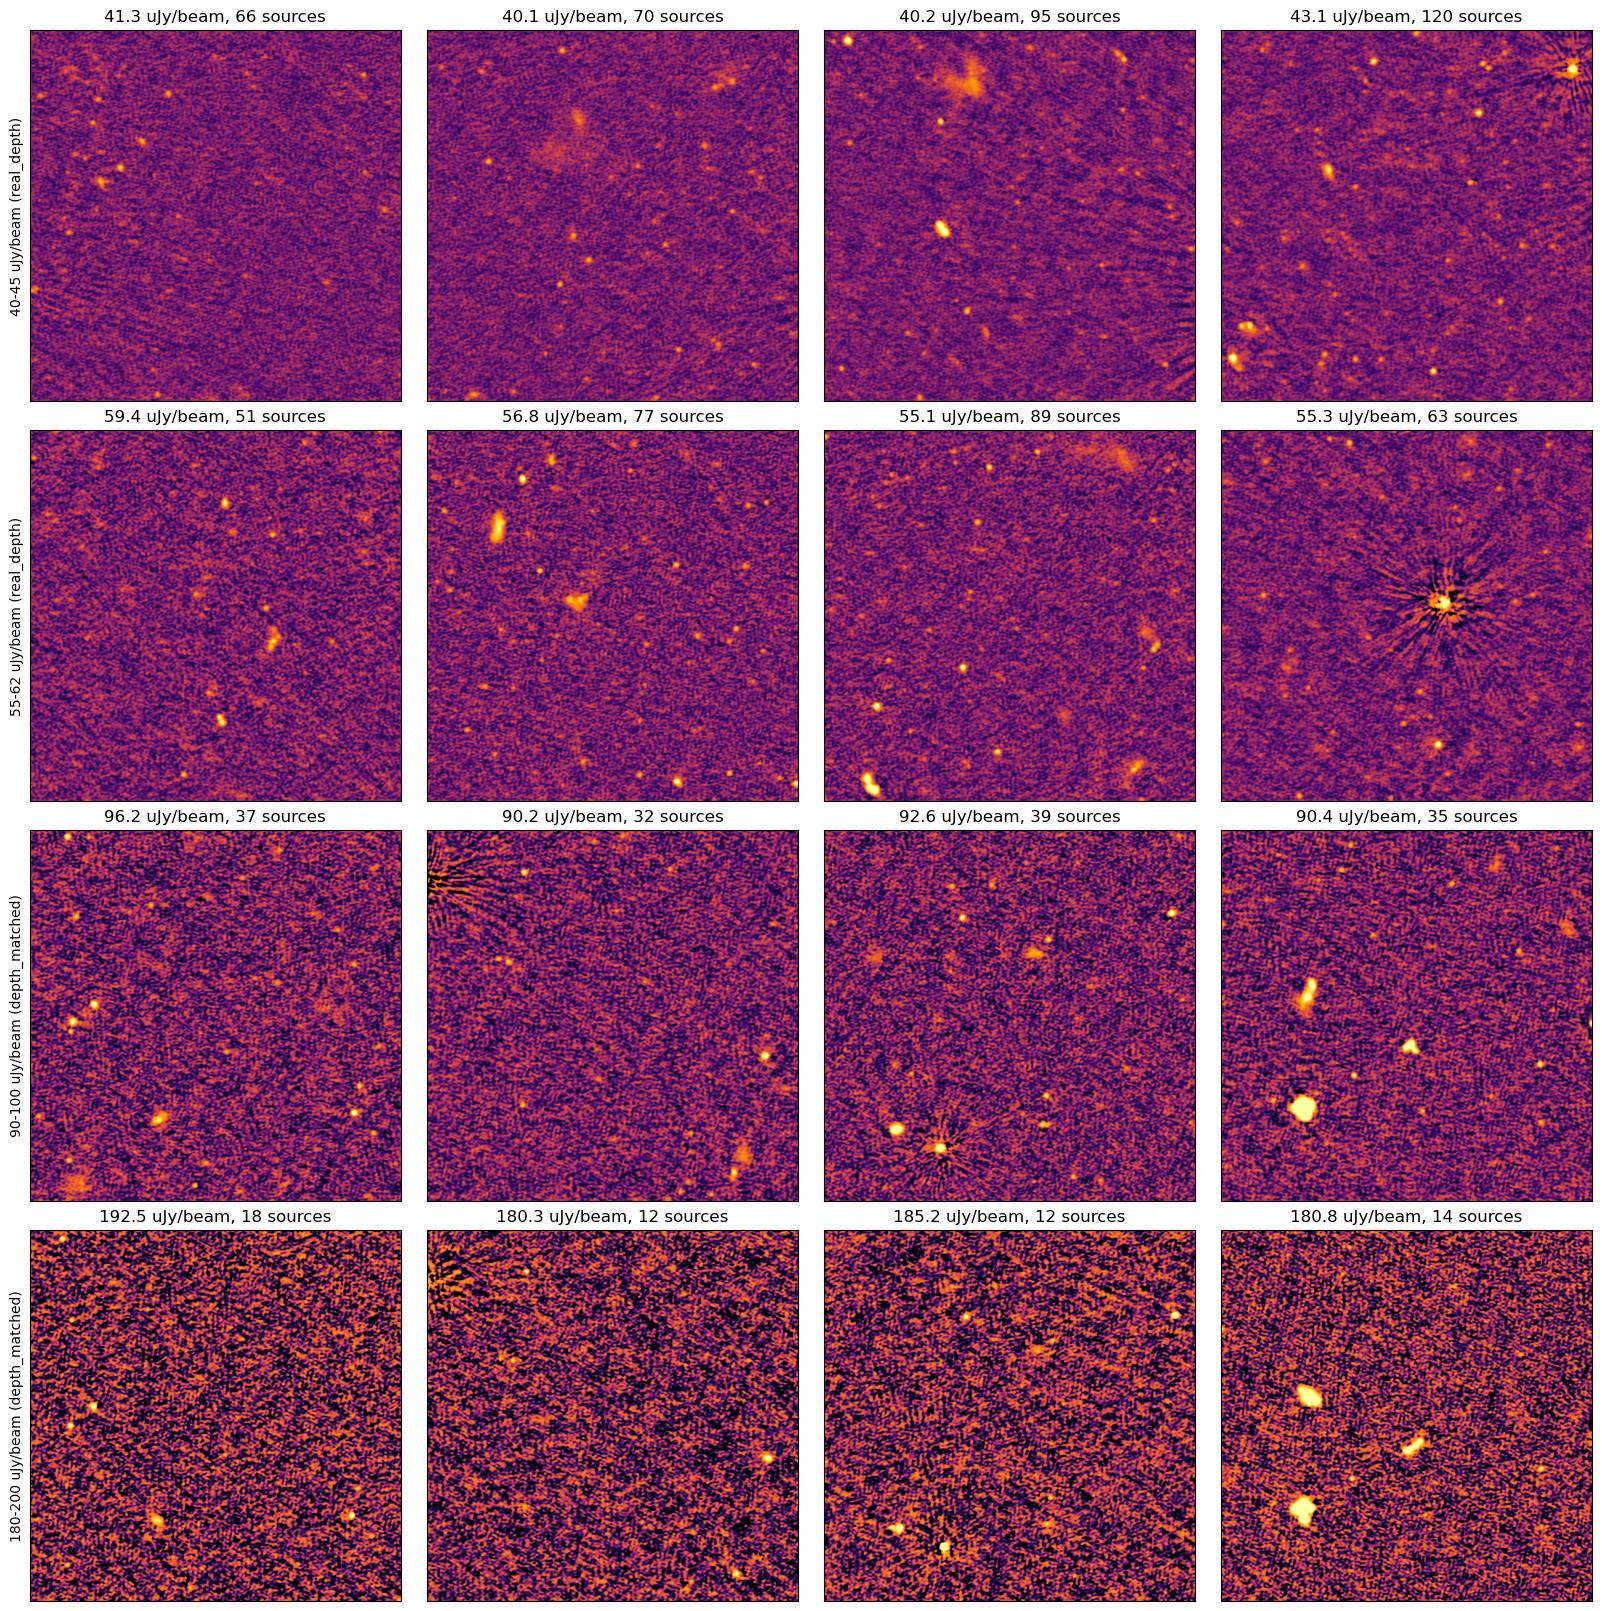

In [10]:
bands = [(40, 45), (55, 62), (90, 100), (180, 200)]
n_per_band = 4

fig, ax = plt.subplots(len(bands), n_per_band, figsize=(4 * n_per_band, 4 * len(bands)), constrained_layout=True)
for row, (lo, hi) in zip(ax, bands):
    brun = OUT / f"images_{lo}-{hi}"
    with contextlib.redirect_stdout(io.StringIO()):
        single.sample(lo, hi, n=n_per_band, out_dir=brun, seed=0)
    bsum = pd.read_csv(brun / "summary.csv")
    btruth = pd.read_csv(brun / "truth_catalog.csv")
    for a, (_, b) in zip(row, bsum.iterrows()):
        show(fits.getdata(brun / b.file) * 1e6, a)
        a.set(xticks=[], yticks=[], title=f"{b.noise_uJy:.1f} uJy/beam, {(btruth.image_id == b.image_id).sum()} sources")
    row[0].set_ylabel(f"{lo}-{hi} uJy/beam ({bsum['mode'].iloc[0]})")
plt.show()

## 6. Testing a source finder against the truth catalog

To test your own source finder, run it on the FITS images and compare its catalog with `truth_catalog.csv`. Three
things to know:

- Matching radius ~12" (8 px): Generated sources sit 2–3 px off their catalog position, because the catalog is
  stored on 6" cells.
- Compare against `peak_flux`/`total_flux`, not the `*_input` columns: they hold the flux in the image, including the
  flux factor of the image and the compression of bright sources (section 4). This is right on average, not per source:
  single sources scatter by a factor of about 1.4 at 200–500 mJy.
- Unmatched detections are not necessarily false: The model adds some faint emission of its own (below the
  catalog depth), which is not in the truth catalog.

                        n  completeness  flux_ratio_median
snr_bin                                                   
[3.0, 5.0)            189         0.873              1.143
[5.0, 7.0)            178         0.955              1.021
[7.0, 10.0)           132         0.970              1.012
[10.0, 20.0)           94         0.989              0.999
[20.0, 50.0)           43         0.977              0.995
[50.0, 1000000000.0)   31         0.968              1.000


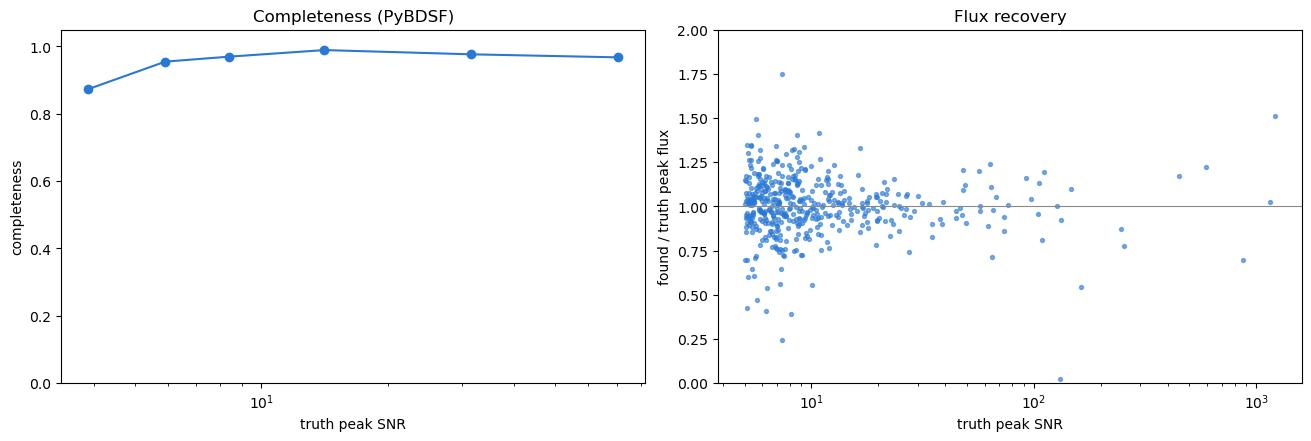

728 detections, 647 matched to the truth catalog, ~81 unmatched (faint emission of the model or spurious)


In [11]:
MATCH_PX = 8.0   # 12"

def evaluate(found, truth, summary, radius_px=MATCH_PX):
    # nearest detection within radius_px for every truth source, per image
    rows = []
    for _, s in summary.iterrows():
        t = truth[truth.image_id == s.image_id].copy()
        f = found[found.image_id == s.image_id]
        t["snr"] = t.peak_flux * 1e6 / s.noise_uJy
        if len(f):
            d, j = cKDTree(f[["x_px", "y_px"]].values).query(t[["x_px", "y_px"]].values)
            t["detected"] = d < radius_px
            t["found_peak"] = np.where(t.detected, f.Peak_flux.values[j] if "Peak_flux" in f else f.peak_flux.values[j], np.nan)
        else:
            t["detected"], t["found_peak"] = False, np.nan
        rows.append(t)
    return pd.concat(rows, ignore_index=True)

ev = evaluate(found, truth, summary)
bins = [3, 5, 7, 10, 20, 50, 1e9]
ev["snr_bin"] = pd.cut(ev.snr, bins, right=False)
table = ev.groupby("snr_bin", observed=True).agg(n=("detected", "size"), completeness=("detected", "mean"))
table["flux_ratio_median"] = ev[ev.detected].groupby("snr_bin", observed=True).apply(
    lambda d: np.median(d.found_peak / d.peak_flux))
print(table.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), constrained_layout=True)
mid = [np.sqrt(b.left * min(b.right, 100)) for b in table.index]   # bin centres (last bin: 50-100)
ax[0].plot(mid, table.completeness.values, "o-", color="#2a78d6")
ax[0].set(xscale="log", xlabel="truth peak SNR", ylabel="completeness", ylim=(0, 1.05), title="Completeness (PyBDSF)")
d = ev[ev.detected & (ev.snr >= 5)]
ax[1].scatter(d.snr, d.found_peak / d.peak_flux, s=8, color="#2a78d6", alpha=0.6)
ax[1].axhline(1, color="#8a8984", lw=0.8)
ax[1].set(xscale="log", xlabel="truth peak SNR", ylabel="found / truth peak flux", ylim=(0, 2), title="Flux recovery")
plt.show()
n_extra = len(found) - ev.detected.sum()
print(f"{len(found)} detections, {ev.detected.sum()} matched to the truth catalog, ~{n_extra} unmatched "
      "(faint emission of the model or spurious)")

## 7. Large maps

`NoiseBandMapSampler` makes maps of any size (512 + k×256 px, at least 1024; calibrated at 2048 px = 51') with SWIIT,
the tiled sampler, always from a depth-matched catalog. The differences to single images:

- Noise of a map is the median of its rms map; the map is rescaled as a whole so that this median lies in the
  band (valid range 50–224 µJy/beam).
- Flattening: SWIIT maps drift in noise over several arcminutes, more than real DR3. By default each map is multiplied
  by a smooth factor that removes this drift (`flatten=False` or `--no-flatten` keeps it). Sources and noise are scaled
  together, so spokes and noise peaks around bright sources stay. The background spread of 256 px blocks (95th/5th
  percentile) falls from 1.36–1.72 to 1.14–1.25; real DR3 has 1.20. Neighbouring blocks change about as gradually as in real DR3.
  The factor is in the truth catalog (`flatten_factor`).
- Noise still rises around bright sources, as in real DR3. Use the delivered rms map for local signal-to-noise
  ratios.
- Fluxes: SWIIT maps come out with fluxes below the catalog, by a factor of 0.56–0.96 per map, depending on the field. Each
  map's truth catalog is therefore calibrated with the map's own bright sources (`FLUXFAC` in the header), and uses the
  brightness curve of the maps (section 4). It also includes the flattening.
- Time: about 3.3 min of GPU time per 2048 px map when 8 maps are generated together (`batch_size`), ~9 min for a
  single map, plus 2–3 min of PyBDSF per map.

The cell below makes one 2048 px map. Set `RUN_MAPS = False` to skip it.

In [12]:
RUN_MAPS = True

if RUN_MAPS:
    mrun = OUT / "maps_60-80"
    with contextlib.redirect_stdout(io.StringIO()):
        mreport = maps.sample(60, 80, n=1, out_dir=mrun, map_px=2048, seed=0)
    print(json.dumps({k: mreport[k] for k in ["n_kept", "n_generated", "rejected", "noise_kept_uJy", "seconds"]}, indent=1))
    msum = pd.read_csv(mrun / "summary.csv")
    display(msum[["map_id", "file", "noise_uJy", "rescale", "flux_factor", "flux_factor_from", "rms_spread",
                  "rms_spread_unflattened", "flatten_min", "flatten_max", "texture_ok_frac"]].round(3))

{
 "n_kept": 1,
 "n_generated": 1,
 "rejected": {},
 "noise_kept_uJy": {
  "min": 64.84,
  "p50": 64.84,
  "max": 64.84
 },
 "seconds": 808
}


,map_id,file,noise_uJy,rescale,flux_factor,flux_factor_from,rms_spread,rms_spread_unflattened,flatten_min,flatten_max,texture_ok_frac
0,0,maps/map_00000.fits,64.842,0.962,0.816,map,1.2,1.358,0.901,1.216,1.0


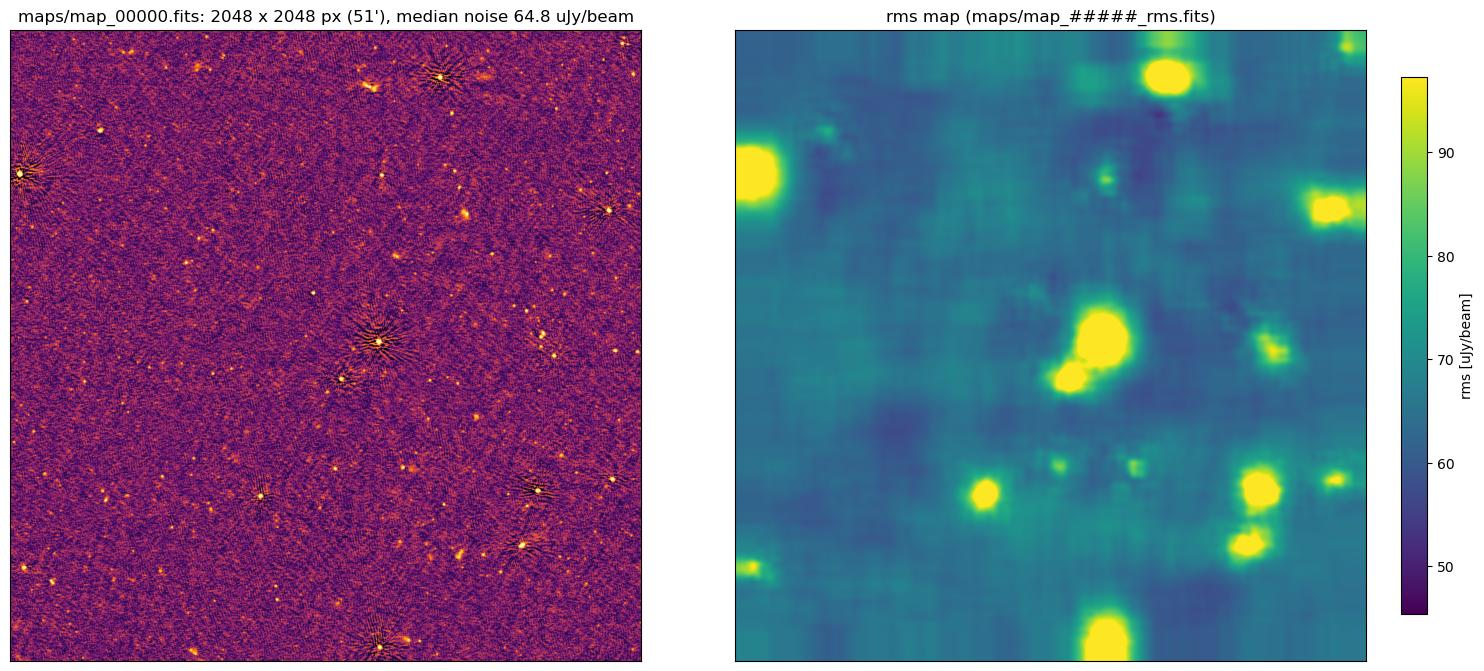

    x_px  y_px  peak_flux  synthetic  detected  snr_local  snr_median
0   57.5   1.5     0.0003       True     False     4.6941      4.9584
1  773.5   1.5     0.0003       True      True     4.7703      4.7562
2  689.5   5.5     0.0005      False      True     7.1668      7.2048
3   29.5   9.5     0.0003       True      True     4.8010      5.0706
4  241.5   9.5     0.0015      False      True    22.9642     22.5495


In [13]:
if RUN_MAPS:
    s = msum.iloc[0]
    img = fits.getdata(mrun / s.file) * 1e6
    rms = fits.getdata(mrun / s.rms_file) * 1e6
    mtruth = pd.read_csv(mrun / "truth_catalog.csv")

    fig, ax = plt.subplots(1, 2, figsize=(15, 6.6), constrained_layout=True)
    show(img, ax[0])
    ax[0].set(xticks=[], yticks=[], title=f"{s.file}: 2048 x 2048 px (51'), median noise {s.noise_uJy:.1f} uJy/beam")
    im = ax[1].imshow(rms, origin="lower", cmap="viridis", vmin=0.7 * s.noise_uJy, vmax=1.5 * s.noise_uJy)
    ax[1].set(xticks=[], yticks=[], title="rms map (maps/map_#####_rms.fits)")
    fig.colorbar(im, ax=ax[1], shrink=0.85, label="rms [uJy/beam]")
    plt.show()

    # local SNR of every truth source, from the rms map at its position
    iy, ix = mtruth.y_px.round().astype(int).clip(0, rms.shape[0] - 1), mtruth.x_px.round().astype(int).clip(0, rms.shape[1] - 1)
    mtruth["snr_local"] = mtruth.peak_flux * 1e6 / rms[iy, ix]
    mtruth["snr_median"] = mtruth.peak_flux * 1e6 / s.noise_uJy
    print(mtruth[["x_px", "y_px", "peak_flux", "synthetic", "detected", "snr_local", "snr_median"]].head().round(4))

## 8. Limitations, command-line use

Limitations:

- Positions are on the 6" grid of the catalog; generated sources sit 2–3 px off. Match with ~12".
- Bright sources in the images are fainter than in the real sky, more so the higher their SNR (section 4). The truth
  catalog includes this, but the images are not (yet) corrected, so do not use them for the bright end of the flux distribution. Detection is not affected.
- The truth catalog is right on average, not per source. On images and maps held out from the fits, median PyBDSF
  peak / truth is 0.90–1.02 up to 500 mJy in all modes. The 16–84 % range of single sources is 0.89–1.12 below 5 mJy and
  0.69–1.44 at 200–500 mJy. Above 500 mJy samples are small and values reach 1.39 (depth-matched images above 1 Jy, n=23).
- Artefacts in large maps are present but somewhat weaker than in real DR3 (same sources above 200 mJy at 1–2': 64 against
  78 µJy/beam). In real-depth single images they match on the same sources (211/90/24 against 218/92/24 µJy/beam at
  24–60" / 1–2' / 2–4').
- Images with bright sources are dropped more often at low noise, mostly by the texture check: 49 % of those at 40–65 µJy/beam
  on fields with a source ≥ 150 mJy, against 6–12 % on random fields. In random-field runs below 55 µJy/beam, 3 % of the images
  hold a source ≥ 200 mJy, against 6–8 % of real tiles of that noise.
- Faint emission the model adds on its own, below the catalog depth, is not listed.
- The images are generated, not observed: they reproduce LoTSS-like noise, artefacts and source morphologies
  statistically, not a real field pixel by pixel.

Command line:

```bash
python scripts/generate_noise_images.py --noise 40-55 --n 100 --out noise_40-55 --gpu 0
python scripts/generate_noise_maps.py   --noise 60-80 --n 8 --size 2048 --out maps_60-80 --gpu 0
```

Each run writes `report.json` with the request, the number of generated and rejected images and the code version
(`CODEVER` in every FITS header), so a dataset can always be traced back.